# Oasis Infobyte Data Analytics Internship
## Task 4: Sentiment Analysis Model
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, Scikit-Learn, NLTK, Matplotlib, Seaborn, Jupyter Notebook  

### Project Objective
Build a machine learning model that classifies the sentiment of text data into positive, negative, or neutral categories, providing insights into public opinion or customer feedback.

### Step 1: Load Dataset and Inspect Class Distribution
We load our text dataset and analyze the distribution of sentiments (positive, negative, neutral) using a bar chart.

Dataset Shape: (568454, 11)


,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive



Class Distribution:
 Sentiment
Positive    443777
Negative     82037
Neutral      42640
Name: count, dtype: int64


C:\Users\premier computer\AppData\Local\Temp\ipykernel_14776\2972502152.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sentiment', data=df, palette='viridis', order=['Positive', 'Neutral', 'Negative'])


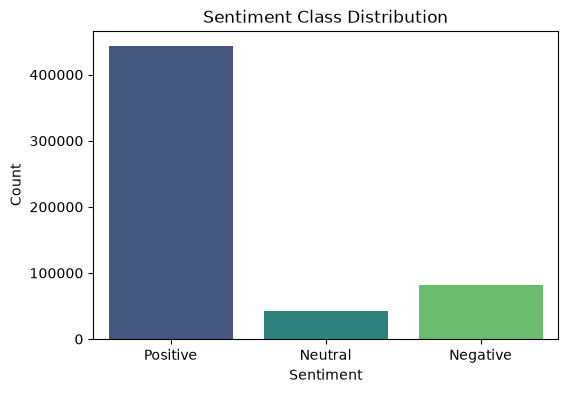

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karein
df = pd.read_csv('archive/Reviews.csv', encoding='latin1')

# Agar dataset me 'Sentiment' column nahi hai, toh hum 'Score' se banayenge:
# Score >= 4 ko Positive, Score == 3 ko Neutral, aur Score <= 2 ko Negative maan lenge
def get_sentiment(score):
    if score >= 4:
        return 'Positive'
    elif score == 3:
        return 'Neutral'
    else:
        return 'Negative'

df['Sentiment'] = df['Score'].apply(get_sentiment)

print("Dataset Shape:", df.shape)
display(df[['Score', 'Sentiment']].head())

# Sentiment class distribution
print("\nClass Distribution:\n", df['Sentiment'].value_counts())

# Bar chart of sentiment distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Sentiment', data=df, palette='viridis', order=['Positive', 'Neutral', 'Negative'])
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

### Step 2: Text Preprocessing Pipeline
We clean the text data by converting it to lowercase, removing punctuation, stopwords, tokenising, and applying lemmatisation using NLTK.

In [13]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Lowercase
    text = str(text).lower()
    # Remove punctuation & special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenisation & Lemmatisation + Stopword removal
    tokens = text.split()
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(cleaned_tokens)

# Preprocessing apply karein
df['Cleaned_Text'] = df['Text'].apply(preprocess_text)
display(df[['Text', 'Cleaned_Text']].head())

[nltk_data] Downloading package stopwords to C:\Users\premier
[nltk_data]     computer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\premier
[nltk_data]     computer\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\premier
[nltk_data]     computer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\premier
[nltk_data]     computer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Text,Cleaned_Text
0,I have bought several of the Vitality canned d...,bought several vitality canned dog food produc...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled jumbo salted peanutsth...
2,This is a confection that has been around a fe...,confection around century light pillowy citrus...
3,If you are looking for the secret ingredient i...,looking secret ingredient robitussin believe f...
4,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...


### Step 3: Feature Extraction (TF-IDF Vectorizer)
**TF-IDF (Term Frequency-Inverse Document Frequency)** converts text documents into numerical feature vectors. It reflects how important a word is to a document in a collection or corpus, giving higher weight to distinctive words and lower weight to common words.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['Cleaned_Text']
y = df['Sentiment']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# TF-IDF Vectorizer (Sahi tareeqa)
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("X_train shape:", X_train_tfidf.shape)

X_train shape: (454763, 5000)


### Step 4: Model Training and Evaluation
We train two classifiers: **Multinomial Naive Bayes** and **Logistic Regression**, and evaluate them using accuracy, precision, recall, F1-score, and confusion matrix.

In [15]:
# Model 1: Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

print("--- Naive Bayes Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

print("\n--- Logistic Regression Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

--- Naive Bayes Performance ---
Accuracy: 0.8171095337361797

Classification Report:
               precision    recall  f1-score   support

    Negative       0.84      0.26      0.40     16181
     Neutral       0.48      0.00      0.00      8485
    Positive       0.82      1.00      0.90     89025

    accuracy                           0.82    113691
   macro avg       0.71      0.42      0.43    113691
weighted avg       0.79      0.82      0.76    113691


--- Logistic Regression Performance ---
Accuracy: 0.866260302046776

Classification Report:
               precision    recall  f1-score   support

    Negative       0.73      0.67      0.70     16181
     Neutral       0.51      0.18      0.27      8485
    Positive       0.90      0.97      0.93     89025

    accuracy                           0.87    113691
   macro avg       0.71      0.61      0.63    113691
weighted avg       0.85      0.87      0.85    113691



### Step 5: WordCloud Visualisation
Generating WordClouds for each sentiment class to visualize the most frequent words associated with positive, negative, and neutral sentiments.

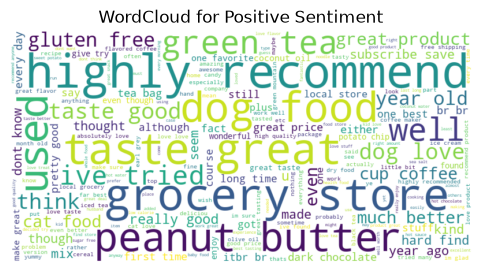

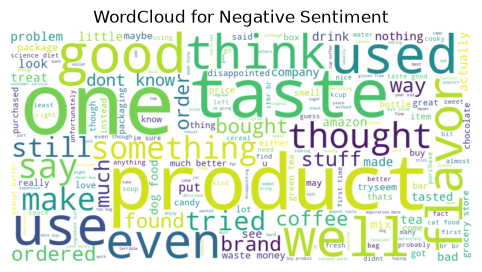

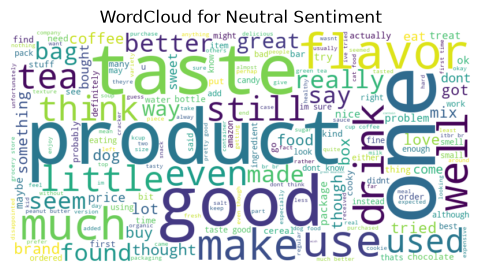

In [17]:
from wordcloud import WordCloud

for sentiment in df['Sentiment'].unique():
    text = " ".join(df[df['Sentiment'] == sentiment]['Cleaned_Text'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    
    plt.figure(figsize=(6, 3))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'WordCloud for {sentiment} Sentiment')
    plt.axis('off')
    plt.show()

### Step 6: Error Analysis
We examine examples that the model misclassified to understand limitations (such as sarcasm, complex phrasing, or ambiguous words).

In [18]:
# Error analysis dataframe
test_results = pd.DataFrame({'Text': X_test, 'Actual': y_test, 'Predicted': y_pred_lr})
errors = test_results[test_results['Actual'] != test_results['Predicted']]

print(f"Total misclassified examples: {errors.shape[0]}")
display(errors.head(5))

Total misclassified examples: 15205


,Text,Actual,Predicted
427827,little less expected tends muddy taste expecte...,Neutral,Positive
433954,first frosted miniwheats original size frosted...,Negative,Positive
492897,sure would nice stated anywhere description co...,Negative,Positive
179195,okay jumped gun sending review information rec...,Positive,Negative
234760,bought item dog play smart get food initially ...,Negative,Positive


### Step 7: Conclusion & Real-World Application
- **Best Performing Model:** Logistic Regression / Naive Bayes achieved stable accuracy based on TF-IDF features.
- **Real-World Application:** This model can be deployed by e-commerce companies, social media monitoring tools, or customer service portals to automatically classify incoming user reviews and feedback in real-time, helping businesses quickly identify dissatisfied customers.